# Recumbent fold — Fourier-seed ensembles

The NF and LDI fits of `01b_recumbent_fold_fit`, repeated for an ensemble of
Fourier seeds. Observations, constraints, architecture, length-scale range,
optimiser and training length are held fixed; only the seed of the random
Fourier basis changes. Every setting is read from the `fit_settings.json` that
`01b` writes, so each member is fitted exactly as the single fit was. This is a
random-feature sensitivity ensemble, not a posterior distribution.

For every member: the loss, the gradient extrema (bubbles in a scalar field)
and, with the synthetic data, the **agreement of its lithology with the true
units**: the share of grid cells in the true unit, over the whole grid and per
true unit, scored as in `01b`.

Computation and diagnostics only; the plots here are not saved. Saved to
`results/<DATASET>/`, for the figures (`01e_recumbent_fold_figures`):

- `ensemble_nf.npz`, `ensemble_ldi.npz` — seeds, losses, extrema, lithology
  entropy, each member's contacts and, with synthetic data, each member's
  agreement and the share of members matching the truth per grid cell
- `ensemble_members.csv` — one row per member and method


## Setup

In [1]:
%matplotlib inline
import json
import random
import sys
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
import diagnostics
figstyle.apply()

import curlew
from curlew.core import CSet, HSet
from curlew.geometry import Grid
from curlew.fields.series import FSF
from curlew.geology import restore, strati
from curlew.kinematics.euler import euler_velocity
from curlew.kinematics.training import SpectralWarmup

import recumbent_inputs  # data loading and grid shared with 01b and 01c

curlew.device = "cuda" if torch.cuda.is_available() else "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 2

SEED = 404
random.seed(SEED)
np.random.seed(SEED)

DATASET = "synthetic"
DATA_DIR = Path("./data")
OUT_DIR = Path("./results") / DATASET
P = json.loads((OUT_DIR / "fit_settings.json").read_text())  # written by 01b
print(json.dumps(P, indent=1))


{
 "lsr_nf": [
  987.3689731521758,
  3949.4758926087034
 ],
 "lsr_ldi": [
  987.3689731521758,
  3949.4758926087034
 ],
 "n_features": 256,
 "n_features_ldi": 256,
 "modes_per_octave": 128,
 "band_info": {
  "m0": null,
  "m2": 1.3544707255474664,
  "m4": 5.484921392403393e-05,
  "lambda_x": 987.3689731521758,
  "lambda_0": null,
  "normal": [
   -0.26142865581734426,
   0.9652228022159116
  ],
  "normal_from_contacts": false,
  "resolved": false,
  "lambda_x_error": null,
  "n_curvature": 9.529411764705882,
  "window": null,
  "contact_noise": null,
  "n_eff": 1.0000000000000002,
  "n_bedding": 8,
  "n_contacts": 14,
  "n_pairs": 10,
  "n_windows": 0,
  "n_horizons_spanning": 0,
  "profile": false,
  "diameter": 1027.7482096227357,
  "strain": null
 },
 "n_directions": 32,
 "fourier_seed": 42,
 "depth_axis": 1,
 "iq_samples": 16,
 "weights": {
  "grad_loss": "1e0",
  "eq_loss": "1e-1"
 },
 "epochs_nf": 3000,
 "epochs_ldi": 2000,
 "n_steps": 0,
 "integrator": "shear",
 "lr_adam_nf": 0

## Data, constraints, grid and truth

The same data, constraints and grid as `01b`, through `recumbent_inputs`.

In [2]:
section = recumbent_inputs.load_section(DATASET, DATA_DIR)
horizon_names, horizons = section["horizon_names"], section["horizons"]
gp, gv, origin = section["gp"], section["gv"], section["origin"]
horizon_colors = {name: figstyle.HORIZON_PALETTE[i % len(figstyle.HORIZON_PALETTE)]
                  for i, name in enumerate(horizon_names)}
anchor = torch.zeros(2, dtype=curlew.dtype, device=curlew.device)

# Younger (H0) shallower than older (H1) on restored depth, as in 01b.
C = CSet(gp=gp, gv=gv, eq=horizons, iq=(P["iq_samples"], [(horizons[0], horizons[1], "<")]))
H_implicit = HSet().zero(**P["weights"])
H_restore = HSet().zero(**P["weights"])

G = Grid((1200, 1200), step=(5.0, 5.0), center=np.zeros(2), sampleArgs=dict(N=128))
domaxes = G.tformed_axes
assert all(np.allclose(a, b) for a, b in zip(domaxes, recumbent_inputs.grid_axes()))
grd = torch.tensor(G.coords(), dtype=curlew.dtype, device=curlew.device)
xlim = (float(domaxes[0][0]), float(domaxes[0][-1]))
zlim = (float(domaxes[1][0]), float(domaxes[1][-1]))

unit_true = None
N_UNITS = len(horizons) + 1
if DATASET == "synthetic":
    unit_true = recumbent_inputs.true_units(domaxes[0], domaxes[1], origin, DATA_DIR)


def match_units(litho):
    # Lithology IDs -> true units: flip the order if it runs against the truth.
    litho = np.asarray(litho, dtype=int)
    corr = np.corrcoef(litho.ravel(), unit_true.ravel())[0, 1]
    return N_UNITS + 1 - litho if corr < 0 else litho


def agreement(litho):
    unit = match_units(litho)
    return dict(volume=float(np.mean(unit == unit_true)),
                per_unit={u: float(np.mean(unit[unit_true == u] == u)) for u in range(1, N_UNITS + 1)})


print(f"horizons {[len(h) for h in horizons]}, bedding {len(gp)}, grid {G.shape}")

horizons [8, 6], bedding 8, grid (240, 240)


## Members

`N_ENSEMBLE` Fourier seeds, the first being the single fit's seed. Torch is
reseeded per member, so the ensemble is reproducible; the first member is a
refit of `01b`'s single fit and can differ from it slightly through the
random initial weights. Each member is scored as it finishes.

In [5]:
N_ENSEMBLE = 15

seed_rng = np.random.default_rng(P["fourier_seed"] + 91)
ENSEMBLE_SEEDS = [int(P["fourier_seed"])]
while len(ENSEMBLE_SEEDS) < N_ENSEMBLE:
    candidate = int(seed_rng.integers(0, 2**31 - 1))
    if candidate not in ENSEMBLE_SEEDS:
        ENSEMBLE_SEEDS.append(candidate)
ENSEMBLE_SEEDS = np.asarray(ENSEMBLE_SEEDS, dtype=np.int64)


def make_nf(seed, member):
    event = strati(
        f"recumbent_fold_nf_seed_{member:02d}", type=FSF, activation="cubic", freq_damp=0.,
        rff_features=P["n_features"], n_directions=P["n_directions"], learning_rate=P["lr_adam"],
        length_scale_range=tuple(P["lsr_nf"]), seed=int(seed), C=C, H=H_implicit,
    )
    for name, h in zip(reversed(horizon_names), reversed(horizons)):
        event.addIsosurface(name, seed=h)
    return curlew.GeoModel([event]), event


def make_ldi(seed, member):
    velocity = euler_velocity(
        2, n_features=P.get("n_features_ldi", P["n_features"]), n_directions=P["n_directions"], seed=int(seed),
        length_scale_range=tuple(P["lsr_ldi"]), stream="alpha", activation="cubic",
        energy_normalised=P.get("energy_normalised", False),
    )
    optimizer = None
    if "lr_sgd" in P:
        optimizer = {
            "amplitude": (torch.optim.SGD, dict(lr=P["lr_sgd"], momentum=P["amp_momentum"], nesterov=True)),
            "shape": (torch.optim.Adam, dict(lr=P["lr_adam"])),
        }
    event = restore(
        f"recumbent_fold_ldi_seed_{member:02d}", C=C, H=H_restore, velocity=velocity,
        n_steps=P["n_steps"], integrator=P["integrator"],
        init_std=P["init_std"], sigma_floor=0.0, signed_normals=True,
        learning_rate=P["lr_adam"], optimizer=optimizer, pin=anchor,
    )
    for name, h in zip(reversed(horizon_names), reversed(horizons)):
        event.addIsosurface(name, seed=h)
    return curlew.GeoModel([event]), event


def fit_ensemble(kind):
    make, epochs = (make_nf, P["epochs_nf"]) if kind == "NF" else (make_ldi, P["epochs_ldi"])
    models, events, losses = [], [], []
    t0 = perf_counter()
    for member, seed in enumerate(ENSEMBLE_SEEDS, start=1):
        torch.manual_seed(SEED + member)
        model, event = make(seed, member)
        if kind == "LDI" and P.get("spectral_warmup"):   # as in 01b: octaves opened longest first
            with SpectralWarmup(event, ramp=P.get("warmup_ramp")) as schedule:
                model.prefit(epochs=epochs, vb=True, early_stop=None, best=True, schedule=schedule)
        else:
            model.prefit(epochs=epochs, vb=True, early_stop=None, best=True)
        loss = float(event.loss().total().detach().cpu())
        msg = f"{kind}: member {member:02d}/{N_ENSEMBLE}, seed={int(seed)}, loss={loss:.3g}"
        if unit_true is not None:
            with torch.no_grad():
                litho = G.reshape(np.asarray(model.predict(grd, litho=True).lithoID))
            msg += f", agreement {100 * agreement(litho)['volume']:.1f}%"
        print(msg)
        models.append(model)
        events.append(event)
        losses.append(loss)
    print(f"{kind}: {perf_counter() - t0:.1f} s")
    return models, events, np.asarray(losses)


models_nf, events_nf, losses_nf = fit_ensemble("NF")
models_ldi, events_ldi, losses_ldi = fit_ensemble("LDI")

L=0.000 grad_loss=0.000 eq_loss=0.000: : 3000/3000|


NF: member 01/15, seed=42, loss=1.22e-05, agreement 87.6%


L=0.000 grad_loss=0.000 eq_loss=0.000: : 3000/3000|


NF: member 02/15, seed=1123574222, loss=1.63e-05, agreement 83.1%


L=0.000 grad_loss=0.000 eq_loss=0.000: : 3000/3000|


NF: member 03/15, seed=2094121401, loss=6.05e-06, agreement 89.6%


... (50 outputs left out)

L=0.000 grad_loss=0.000 eq_loss=0.000: : 2000/2000|


LDI: member 14/15, seed=1129350089, loss=4.4e-14, agreement 93.7%


L=0.000 grad_loss=0.000 eq_loss=0.000: : 2000/2000|


LDI: member 15/15, seed=1766903757, loss=1.22e-14, agreement 92.6%
LDI: 219.0 s


## Diagnostics

In [6]:
diag = {
    "NF": diagnostics.evaluate_ensemble(models_nf, events_nf, grd, G.shape, domaxes[0], domaxes[1], grid=G),
    "LDI": diagnostics.evaluate_ensemble(models_ldi, events_ldi, grd, G.shape, domaxes[0], domaxes[1], grid=G),
}
losses = {"NF": losses_nf, "LDI": losses_ldi}
classes = np.unique(np.concatenate([d["lithology"].ravel() for d in diag.values()]))
entropy = {k: diagnostics.lithology_entropy(d["lithology"], classes) for k, d in diag.items()}

for k, d in diag.items():
    extrema_total = d["extrema"].sum(axis=1)
    print(f"{k}: loss median {np.median(losses[k]):.3g} [{losses[k].min():.3g}, {losses[k].max():.3g}]; "
          f"members with extrema {np.count_nonzero(extrema_total)}/{N_ENSEMBLE}; "
          f"mean lithology entropy {entropy[k].mean():.3f} bits")

NF: loss median 1.07e-05 [4.73e-06, 1.81e-05]; members with extrema 15/15; mean lithology entropy 0.387 bits
LDI: loss median 4.4e-14 [7.5e-15, 5.38e-08]; members with extrema 0/15; mean lithology entropy 0.044 bits


## Against the true units

Synthetic data only. Whole-box agreement (the share of grid cells in the true unit) is
mostly a score of the extrapolation, where three holes decide nothing, and it barely notices
a closed body. So each member is also scored where the data can decide the geometry
(`recumbent_inputs.score_against_truth`):

- **contact distance**: per horizon, the median distance (m) between the member's contact
  and the true one within the drillholes' window (the outer holes widened by half the mean
  hole spacing), both ways round, so a missing and an extra contact both count;
- **IoU**: per unit, intersection over union with the true unit within that window.

The single Surfe fit of `01c` (`results/synthetic/surfe.npz`) is scored the same way and
shown alongside. Whole-box agreement and `match_fraction` (per grid cell, the share of
members that put it in the true unit) are kept for reference.

In [7]:
rows, agreement_members, match_fraction = [], {}, {}
reference = recumbent_inputs.truth_reference(origin, DATA_DIR) if unit_true is not None else None
for k, d in diag.items():
    extrema_total = d["extrema"].sum(axis=1)
    for m, seed in enumerate(ENSEMBLE_SEEDS):
        row = dict(method=k, member=m + 1, seed=int(seed), loss=float(losses[k][m]),
                   extrema=int(extrema_total[m]), saddles=int(d["saddles"][m]))
        if unit_true is not None:
            a = agreement(d["lithology"][m])
            row.update(agreement=100 * a["volume"],
                       **{f"agreement_unit_{u}": 100 * v for u, v in a["per_unit"].items()})
            s = recumbent_inputs.score_against_truth(match_units(d["lithology"][m]), domaxes[0], domaxes[1],
                                                     unit_true, reference)
            row.update(**{f"contact_distance_{n}": v for n, v in zip(horizon_names, s["contact_distance"])},
                       **{f"iou_unit_{u}": v for u, v in enumerate(s["iou"], start=1)})
        rows.append(row)
    if unit_true is not None:
        units = np.stack([match_units(l) for l in d["lithology"]])
        match_fraction[k] = np.mean(units == unit_true, axis=0)
members = pd.DataFrame(rows)

if unit_true is not None:
    for k in diag:
        t = members[members["method"] == k]
        agreement_members[k] = dict(
            volume=t["agreement"].to_numpy() / 100,
            per_unit=t[[f"agreement_unit_{u}" for u in range(1, N_UNITS + 1)]].to_numpy() / 100,
        )
    summary = members.groupby("method")["agreement"].describe()[["mean", "50%", "min", "max"]]
    print(summary.round(1).rename(columns={"50%": "median"}).to_string())
    # where the data decide: contact distance and IoU within the holes' window
    dist_cols = [f"contact_distance_{n}" for n in horizon_names]
    iou_cols = [f"iou_unit_{u}" for u in range(1, N_UNITS + 1)]
    window = members.groupby("method").agg(
        **{f"{c}_median": (c, "median") for c in dist_cols + iou_cols})
    surfe = np.load(OUT_DIR / "surfe.npz")
    if "contact_distance" in surfe:
        window.loc["Surfe (01c)"] = [*surfe["contact_distance"], *surfe["iou"]]
    print(f"\nwithin x {np.round(reference['window'])} m (Surfe: its single fit; run 01c first):")
    print(window.round(2).to_string())
    by_bubble = members.assign(bubble=members["extrema"] > 0).groupby(["method", "bubble"])["agreement"]
    print(by_bubble.agg(["count", "mean"]).round(1).to_string())
print(members.round(2).to_string(index=False))

        mean  median   min   max
method                          
LDI     93.2    93.5  92.1  94.4
NF      83.7    83.1  76.5  89.7

within x [-503.  430.] m (Surfe: its single fit; run 01c first):
             contact_distance_H0_median  contact_distance_H1_median  iou_unit_1_median  iou_unit_2_median  iou_unit_3_median
method                                                                                                                      
LDI                                5.01                        9.86               0.90               0.81               0.96
NF                                14.69                       15.22               0.78               0.60               0.84
Surfe (01c)                       13.41                       12.50               0.84               0.71               0.91
               count  mean
method bubble             
LDI    False      15  93.2
NF     True       15  83.7
method  member       seed  loss  extrema  saddles  agreement  agreeme

## Visual check

Not saved; the paper figure is made in `01e_recumbent_fold_figures`.
Top: each member's agreement (open markers have a bubble) and, per grid cell,
the share of members matching the truth (true contacts orange). Bottom: every
member's contacts over the lithology entropy.

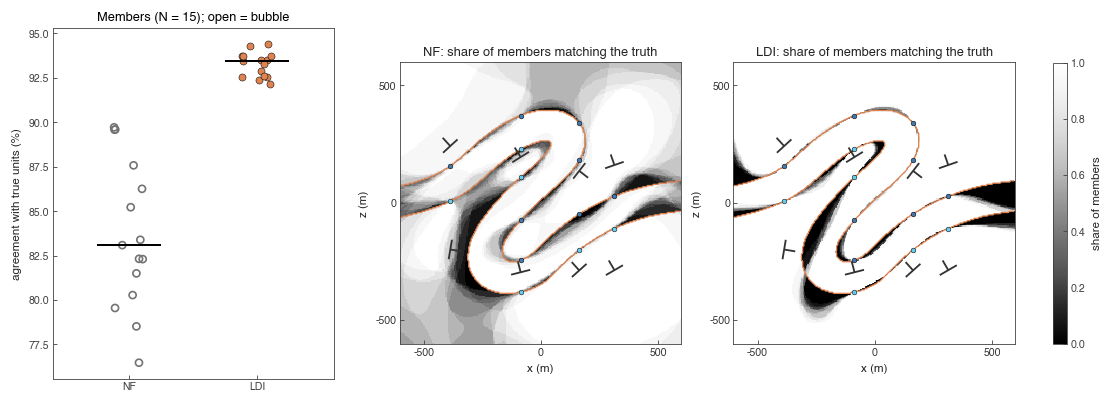

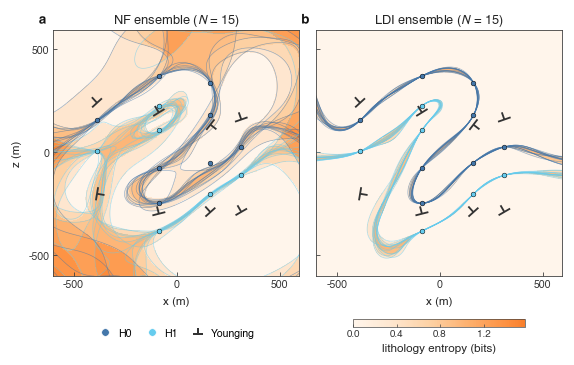

In [8]:
if unit_true is not None:
    fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.8), gridspec_kw=dict(width_ratios=[0.8, 1, 1]))
    ax = axes[0]
    for i, (k, color) in enumerate((("NF", "0.45"), ("LDI", "#DD8452"))):
        t = members[members["method"] == k]
        jitter = np.random.default_rng(0).uniform(-0.12, 0.12, len(t))
        bubble = (t["extrema"] > 0).to_numpy()
        ax.scatter(i + jitter[~bubble], t["agreement"][~bubble], s=18, color=color, edgecolors="k",
                   linewidths=0.3, zorder=3)
        ax.scatter(i + jitter[bubble], t["agreement"][bubble], s=18, facecolors="none", edgecolors=color,
                   linewidths=1.0, zorder=3)
        ax.hlines(t["agreement"].median(), i - 0.25, i + 0.25, color="k", lw=1.2, zorder=4)
    ax.set_xticks([0, 1], ["NF", "LDI"])
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylabel("agreement with true units (%)")
    ax.set_title(f"Members (N = {N_ENSEMBLE}); open = bubble")
    for ax, k in zip(axes[1:], ("NF", "LDI")):
        m = ax.pcolormesh(domaxes[0], domaxes[1], match_fraction[k].T, cmap="Greys_r",
                          vmin=0.0, vmax=1.0, shading="auto", rasterized=True)
        ax.contour(domaxes[0], domaxes[1], unit_true.T, levels=[1.5, 2.5], colors="#DD8452", linewidths=0.8)
        figstyle.overlay_constraints(ax, horizons, horizon_names, gp, gv, colors=horizon_colors,
                                     scatter_s=8, quiver_scale=0.01, legend=False)
        figstyle.format_section_ax(ax, title=f"{k}: share of members matching the truth")
    fig.colorbar(m, ax=axes[1:], shrink=0.8, label="share of members")
    plt.show()

entropy_norm = Normalize(vmin=0.0, vmax=float(np.log2(len(classes))))
fig, grid = figstyle.comparison_grid(1, 2, xlim=xlim, zlim=zlim, width=120.0 / 25.4)
for col, k in enumerate(("NF", "LDI")):
    ax = grid[col]
    mappable = ax.pcolormesh(domaxes[0], domaxes[1], entropy[k].T, cmap=figstyle.entropy_cmap(),
                             norm=entropy_norm, shading="auto", rasterized=True, zorder=0)
    diagnostics.draw_contact_ensemble(ax, diag[k]["scalar"], domaxes[0], domaxes[1],
                                      horizons, horizon_names, gp, gv, colors=horizon_colors)
    figstyle.set_view(ax, xlim, zlim)
    figstyle.format_section_ax(ax, xlabel=True, ylabel=col == 0,
                               title=f"{k} ensemble" + r" ($N$" + f" = {N_ENSEMBLE})")
    figstyle.hide_cbar(grid.cbar_axes[col])
for ax, letter in zip(grid.axes, "ab"):
    figstyle.panel_label(ax, letter)
figstyle.bottom_legend(grid.axes[0], figstyle.constraint_handles(horizon_colors, horizon_names),
                       ncol=len(horizon_names) + 1)
figstyle.bottom_cbar(grid.axes[1], mappable, "lithology entropy (bits)")
plt.show()

## Save

In [9]:
for k, d in diag.items():
    contacts = diagnostics.ensemble_contacts(d["scalar"], domaxes[0], domaxes[1], horizons)
    np.savez_compressed(
        OUT_DIR / f"ensemble_{k.lower()}.npz",
        entropy=entropy[k].astype(np.float32),
        classes=classes,
        seeds=ENSEMBLE_SEEDS,
        losses=losses[k],
        extrema=d["extrema"],
        saddles=d["saddles"],
        minimum_gradient_norm=d["minimum_gradient_norm"],
        stability=d["stability"],
        n_members=len(contacts),
        n_horizons=len(horizons),
        **({"agreement": agreement_members[k]["volume"],
            "agreement_per_unit": agreement_members[k]["per_unit"],
            "match_fraction": match_fraction[k].astype(np.float32)}
           if agreement_members else {}),
        **({"contact_distance": members.loc[members["method"] == k, [f"contact_distance_{n}" for n in horizon_names]].to_numpy(),
            "iou": members.loc[members["method"] == k, [f"iou_unit_{u}" for u in range(1, N_UNITS + 1)]].to_numpy()}
           if agreement_members else {}),
        **diagnostics.pack_contacts(contacts),
    )
members.to_csv(OUT_DIR / "ensemble_members.csv", index=False)
print("wrote ensemble_nf.npz, ensemble_ldi.npz, ensemble_members.csv to", OUT_DIR)

wrote ensemble_nf.npz, ensemble_ldi.npz, ensemble_members.csv to results/synthetic
